In [1]:
# General Imports
import torch
import matplotlib.pyplot as plt

In [2]:
def f(x):
  # Check size
  assert x.shape == (2, 1)
  # Create X and Y
  X = x[0,0]
  Y = x[1,0]
  output = 0.26*(X**2+Y**2) - 0.48*X*Y
  output = output.view(1,1)
  assert output.shape == (1,1)
  return output

# Compute the gradient
def grad_f(x):

  # Check that this is true (we set this before the for loop)
  assert x.requires_grad == True
  y = f(x)
  # Make sure output is as scalar
  assert y.shape == (1,1)
  grad_term = torch.autograd.grad(outputs=y, inputs=x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

  # Save space (and get rid of any weird extra stuff)
  y = y.detach()
  x = x.detach()
  #grad_term = grad_term.detach()


  # Make sure the gradient is the same sizeas the input
  assert grad_term.shape == x.shape

  # Return
  return grad_term

In [3]:
# run gradient descent

def gradient_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term))

  for i in range(max_iters):
    # Gradient descent update
    x = x - step_size * grad_fx

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist

In [4]:
# Set up optimization parameters (picked randomly)
dim = 2
# Played around to try to find a good step size that converages. This takes some guess work
step_size = 1e-1
max_iters = 1000
# random x
x0 = torch.randn(dim,1)
tol = 1e-3

x_opt1, f_hist1, grad_norm_hist1, x_hist1 = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)

i: 0, fx: 6.275e-03, grad_norm: 8.877e-02
i: 1, fx: 5.526e-03, grad_norm: 8.011e-02
i: 2, fx: 4.915e-03, grad_norm: 7.234e-02
i: 3, fx: 4.417e-03, grad_norm: 6.538e-02
i: 4, fx: 4.010e-03, grad_norm: 5.913e-02
i: 5, fx: 3.677e-03, grad_norm: 5.354e-02
i: 6, fx: 3.404e-03, grad_norm: 4.854e-02
i: 7, fx: 3.179e-03, grad_norm: 4.407e-02
i: 8, fx: 2.994e-03, grad_norm: 4.008e-02
i: 9, fx: 2.840e-03, grad_norm: 3.653e-02
i: 10, fx: 2.713e-03, grad_norm: 3.338e-02
i: 11, fx: 2.606e-03, grad_norm: 3.058e-02
i: 12, fx: 2.516e-03, grad_norm: 2.810e-02
i: 13, fx: 2.441e-03, grad_norm: 2.592e-02
i: 14, fx: 2.376e-03, grad_norm: 2.400e-02
i: 15, fx: 2.320e-03, grad_norm: 2.232e-02
i: 16, fx: 2.272e-03, grad_norm: 2.086e-02
i: 17, fx: 2.230e-03, grad_norm: 1.959e-02
i: 18, fx: 2.193e-03, grad_norm: 1.848e-02
i: 19, fx: 2.159e-03, grad_norm: 1.753e-02
i: 20, fx: 2.129e-03, grad_norm: 1.672e-02
i: 21, fx: 2.102e-03, grad_norm: 1.602e-02
i: 22, fx: 2.077e-03, grad_norm: 1.542e-02
i: 23, fx: 2.054e-03,

In [5]:
# Create a 2D grid from -5 to 5

# Define the range and number of points
xx = torch.linspace(-5, 5, 100)
yy = torch.linspace(-5, 5, 100)

## Create a 2D grid
X, Y = torch.meshgrid(xx,yy,indexing='xy') # 'xy' indexing ensures correct indexing for 2D grid

Z = torch.zeros(X.shape)
for i in range(100):
  for j in range(100):
    input_vec = torch.tensor([X[i,j],Y[i,j]]).view(2,1)
    Z[i,j] = f(input_vec).item()



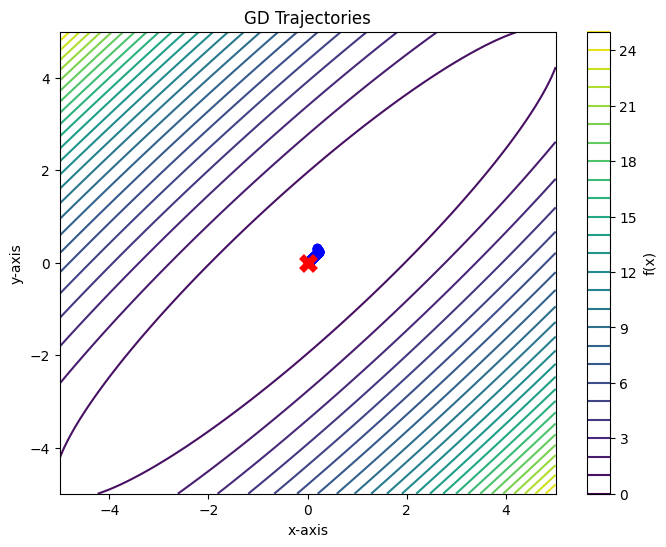

In [6]:
plt.figure(figsize=(8,6))

# Plots the landscape
plt.contour(X,Y,Z,levels=30, cmap='viridis')

#extract x coords
x_coords = [x[0].item() for x in x_hist1]
#extract y coords
y_coords = [x[1].item() for x in x_hist1]

# Plot the gradient descent trajectory
plt.plot(x_coords, y_coords, marker='o', color='blue', label='GD traj 1')

# plot minimizer
plt.plot(0, 0, marker='x', color='red', markersize=10, markeredgewidth=5)


plt.colorbar(label='f(x)')
plt.title('GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.show()